# Model 1: Energy Consumption Prediction for African Food Retail SMEs

**Purpose**: Build an ML model to predict monthly electricity consumption for refrigeration-heavy food retail businesses (butcheries, grocers, mini-supermarkets) in Sub-Saharan Africa.

**Dataset**: CBECS 2018 (US Commercial Buildings Energy Consumption Survey) - adapted for African SMEs

**Approach**: 
- Train on US commercial food retail data
- Adapt predictions for African climate and business contexts
- Provide API-ready model for integration

---


## SECTION 1: Setup & Data Loading

Import all necessary libraries and load the CBECS 2018 dataset.


In [ ]:
# Import all necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import xgboost as xgb
import joblib
import warnings
from scipy import stats
from scipy.stats import normaltest

warnings.filterwarnings('ignore')

# Set style for plots
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

print("✅ All libraries imported successfully")


✅ All libraries imported successfully


In [ ]:
# Load the CBECS 2018 dataset
data_path = 'data\cbecs2018_final_public.csv'
df = pd.read_csv(data_path)

print(f"Dataset shape: {df.shape}")
print(f"\nColumn dtypes:\n{df.dtypes.value_counts()}")
print(f"\nFirst 5 rows:")
df.head()


Dataset shape: (6436, 1249)

Column dtypes:
float64    637
int64      612
Name: count, dtype: int64

First 5 rows:


,PUBID,REGION,CENDIV,PBA,PUBCLIM,SQFT,SQFTC,WLCNS,RFCNS,RFCOOL,...,ZMFBTU,ZMFEXP,ZELCNS,ZELEXP,ZNGCNS,ZNGEXP,ZFKCNS,ZFKEXP,ZDHBTU,ZDHEXP
0,1,3,5,2,3,210000,8,1,4,2,...,0,0,0,0,9,9,1,1,0,0
1,2,4,9,2,4,28000,5,1,6,1,...,0,0,0,0,0,0,9,9,9,9
2,3,3,5,8,4,2100,2,1,4,2,...,0,0,0,0,9,9,9,9,9,9
3,4,3,7,5,5,240000,8,2,6,1,...,0,0,0,0,1,1,9,9,9,9
4,5,1,2,5,3,295000,8,3,6,2,...,0,0,0,0,0,0,9,9,9,9


In [ ]:
# Display all column names
print(f"Total columns: {len(df.columns)}")
print("\nAll column names:")
for i, col in enumerate(df.columns, 1):
    print(f"{i:4d}. {col}")


Total columns: 1249

All column names:
   1. PUBID
   2. REGION
   3. CENDIV
   4. PBA
   5. PUBCLIM
   6. SQFT
   7. SQFTC
   8. WLCNS
   9. RFCNS
  10. RFCOOL
  11. RFTILT
  12. BLDSHP
  13. GLSSPC
  14. NFLOOR
  15. BASEMNT
  16. FLCEILHT
  17. ATTIC
  18. ELEVTR
  19. NELVTR
  20. ESCLTR
  21. NESLTR
  22. YRCONC
  23. RENOV
  24. RENCOS
  25. RENADD
  26. RENRDC
  27. RENINT
  28. RENRFF
  29. RENWIN
  30. RENHVC
  31. RENLGT
  32. RENPLB
  33. RENELC
  34. RENINS
  35. RENSAF
  36. RENSTR
  37. RENOTH
  38. DRYCL
  39. VACANT
  40. PBAPLUS
  41. RWSEAT
  42. PBSEAT
  43. EDSEAT
  44. FDSEAT
  45. DRVTHRU
  46. HCBED
  47. NRSBED
  48. LODGRM
  49. COURT
  50. FACIL
  51. FEDFAC
  52. FACACT
  53. MANIND
  54. PLANT
  55. FACDST
  56. FACDHW
  57. FACDCW
  58. FACELC
  59. BLDPLT
  60. GOVOWN
  61. GOVTYP
  62. OWNTYPE
  63. NOCC
  64. NOCCAT
  65. OWNOCC
  66. OWNOPR
  67. OWNPPR
  68. NWNPPR
  69. NWNOPR
  70. WHOPPR
  71. MONUSE
  72. OCCUPYP
  73. LODOCCP
  74. OPEN24
  75. OP

## SECTION 2: Column Selection & Filtering

Filter the dataset to keep only relevant columns and food-related business types (PBA codes).

**CBECS PBA Codes for Food Retail:**
- **PBA 11**: Food Sales (Grocery stores, supermarkets, convenience stores)
- **PBA 12**: Food Service (Restaurants, cafeterias, fast food)

We'll filter for these PBA codes to focus on food retail businesses.


In [ ]:
# Select only the columns we need
required_columns = [
    'PBA',           # Principal Building Activity (business type)
    'SQFT',          # Square footage
    'WKHRS',         # Weekly operating hours
    'RFGCOMPN',      # Number of refrigeration/freezer units
    'ELCNS',         # Electricity consumption in kWh (TARGET)
    'CENDIV',        # Census division (regional/climate proxy)
    'NFLOOR',        # Number of floors
    'NWKER',         # Number of workers
    'MONUSE',        # Months in use per year
    'YRCONC'         # Year of construction category
]

# Check which columns exist
missing_cols = [col for col in required_columns if col not in df.columns]
if missing_cols:
    print(f"⚠️ Missing columns: {missing_cols}")
else:
    print("✅ All required columns found")

# Select only required columns
df_filtered = df[required_columns].copy()
print(f"\nFiltered dataset shape: {df_filtered.shape}")
df_filtered.head()


✅ All required columns found

Filtered dataset shape: (6436, 10)


,PBA,SQFT,WKHRS,RFGCOMPN,ELCNS,CENDIV,NFLOOR,NWKER,MONUSE,YRCONC
0,2,210000,70,NaN,5483285.0,5,994,350,12,2
1,2,28000,45,NaN,448027.0,9,5,12,12,6
2,8,2100,48,3.0,15354.0,5,1,6,12,6
3,5,240000,55,NaN,578621.0,7,1,34,12,9
4,5,295000,80,NaN,378243.0,2,1,10,12,4


In [ ]:
# Filter for food-related PBA codes
# PBA 11 = Food Sales (Grocery stores, supermarkets)
# PBA 12 = Food Service (Restaurants, cafeterias)

food_pba_codes = [11, 12]
df_food = df_filtered[df_filtered['PBA'].isin(food_pba_codes)].copy()

print(f"Original dataset rows: {len(df_filtered)}")
print(f"Food-related rows after filtering: {len(df_food)}")
print(f"\nPBA value counts:")
print(df_food['PBA'].value_counts().sort_index())
print(f"\nPBA code meanings:")
print("  11 = Food Sales (Grocery stores, supermarkets)")
print("  12 = Food Service (Restaurants, cafeterias)")


Original dataset rows: 6436
Food-related rows after filtering: 294

PBA value counts:
PBA
11     23
12    271
Name: count, dtype: int64

PBA code meanings:
  11 = Food Sales (Grocery stores, supermarkets)
  12 = Food Service (Restaurants, cafeterias)


## SECTION 3: Extensive EDA (Exploratory Data Analysis)

Comprehensive exploratory data analysis to understand the data distribution, relationships, and patterns.


### 3.1 Missing Values Analysis


Missing Values Summary:
          Missing Count  Missing Percentage
RFGCOMPN            232           78.911565


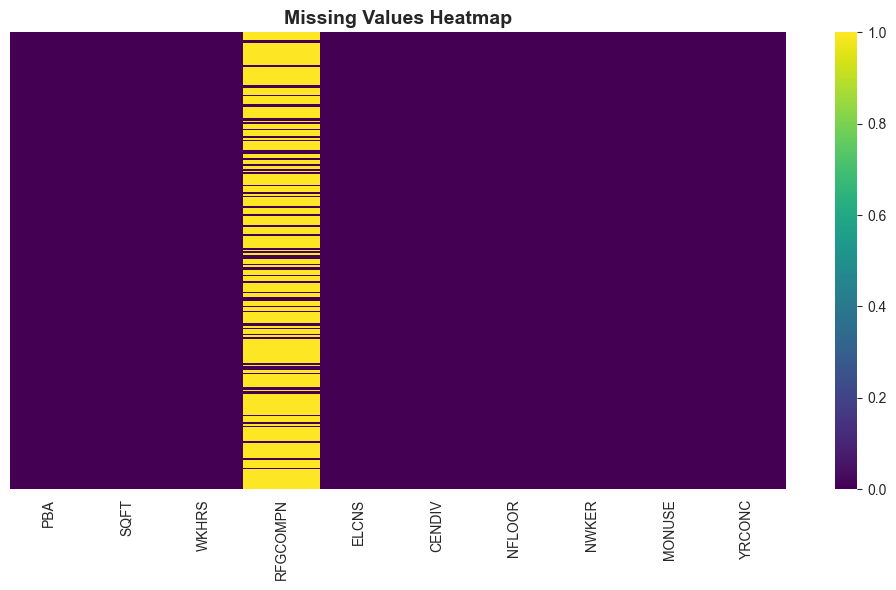

<Figure size 1000x600 with 0 Axes>

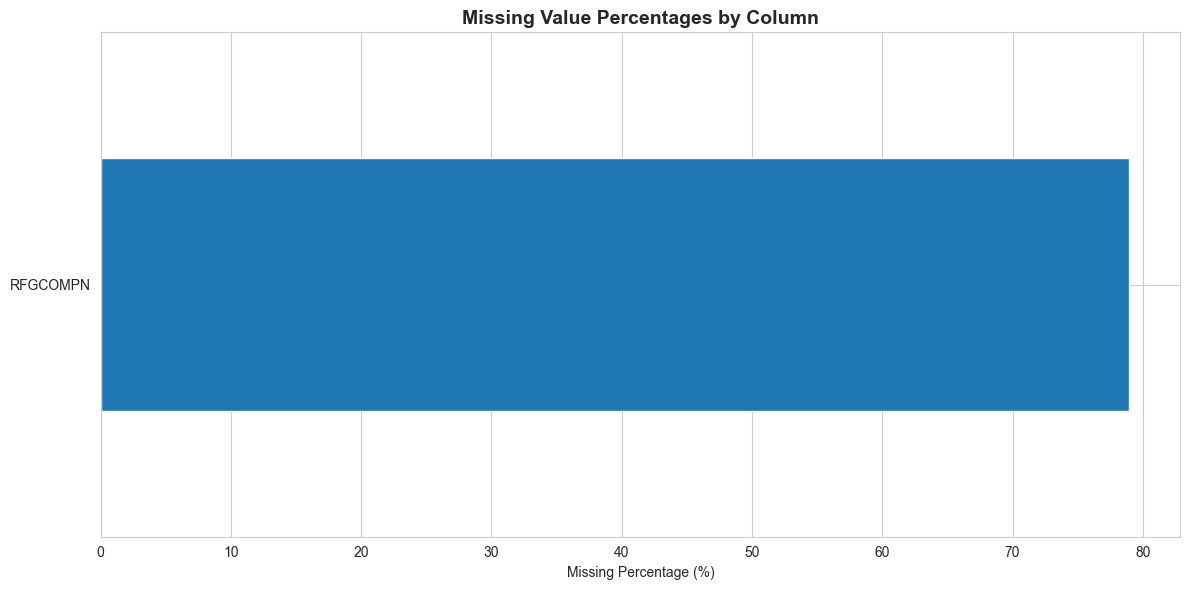

In [ ]:
# Check for missing values
missing_data = df_food.isnull().sum()
missing_pct = (missing_data / len(df_food)) * 100
missing_df = pd.DataFrame({
    'Missing Count': missing_data,
    'Missing Percentage': missing_pct
}).sort_values('Missing Count', ascending=False)

print("Missing Values Summary:")
print(missing_df[missing_df['Missing Count'] > 0])

# Visualize missing values
if missing_data.sum() > 0:
    plt.figure(figsize=(10, 6))
    sns.heatmap(df_food.isnull(), yticklabels=False, cbar=True, cmap='viridis')
    plt.title('Missing Values Heatmap', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    # Bar chart of missing percentages
    plt.figure(figsize=(10, 6))
    missing_df[missing_df['Missing Count'] > 0].plot(kind='barh', y='Missing Percentage', legend=False)
    plt.title('Missing Value Percentages by Column', fontsize=14, fontweight='bold')
    plt.xlabel('Missing Percentage (%)')
    plt.tight_layout()
    plt.show()
else:
    print("\n✅ No missing values found in the dataset!")


### 3.2 Target Variable Analysis (ELCNS)


Rows after removing invalid ELCNS: 294

📊 ELCNS (Electricity Consumption) Statistics:
  Mean        : 632,225.22
  Median      : 69,971.00
  Std         : 1,940,299.40
  Min         : 1,051.00
  Max         : 20,430,447.00
  Skewness    : 5.98
  Kurtosis    : 45.94


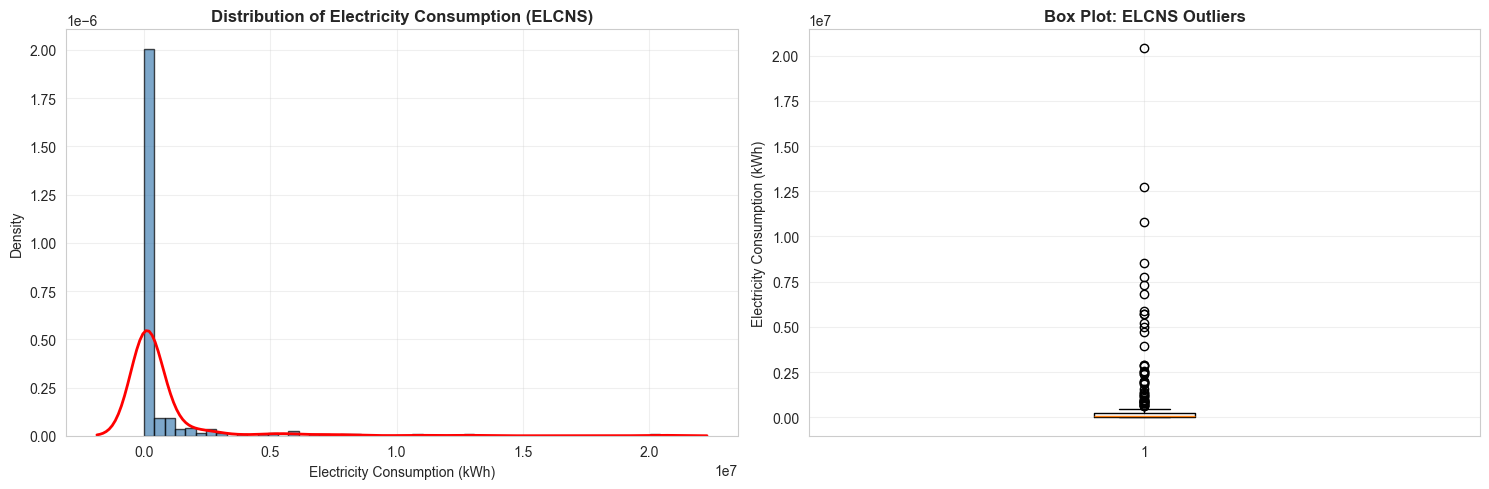

In [ ]:
# Remove rows with missing or invalid ELCNS (target variable)
df_food = df_food[df_food['ELCNS'].notna() & (df_food['ELCNS'] > 0)].copy()
print(f"Rows after removing invalid ELCNS: {len(df_food)}")

# Statistical summary
elcns_stats = {
    'Mean': df_food['ELCNS'].mean(),
    'Median': df_food['ELCNS'].median(),
    'Std': df_food['ELCNS'].std(),
    'Min': df_food['ELCNS'].min(),
    'Max': df_food['ELCNS'].max(),
    'Skewness': df_food['ELCNS'].skew(),
    'Kurtosis': df_food['ELCNS'].kurtosis()
}

print("\n📊 ELCNS (Electricity Consumption) Statistics:")
for key, value in elcns_stats.items():
    print(f"  {key:12s}: {value:,.2f}")

# Distribution plot
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Histogram + KDE
axes[0].hist(df_food['ELCNS'], bins=50, density=True, alpha=0.7, color='steelblue', edgecolor='black')
sns.kdeplot(df_food['ELCNS'], ax=axes[0], color='red', linewidth=2)
axes[0].set_title('Distribution of Electricity Consumption (ELCNS)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Electricity Consumption (kWh)')
axes[0].set_ylabel('Density')
axes[0].grid(True, alpha=0.3)

# Box plot
axes[1].boxplot(df_food['ELCNS'], vert=True)
axes[1].set_title('Box Plot: ELCNS Outliers', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Electricity Consumption (kWh)')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


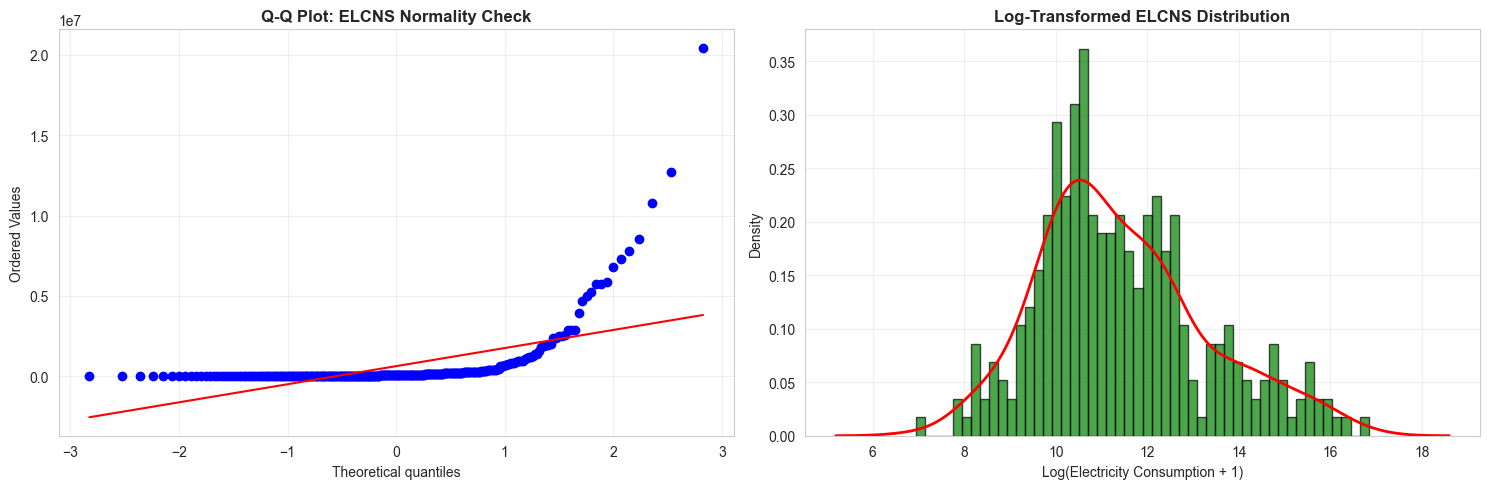

✅ Target variable analysis complete


In [ ]:
# Q-Q plot for normality check
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Q-Q plot
stats.probplot(df_food['ELCNS'], dist="norm", plot=axes[0])
axes[0].set_title('Q-Q Plot: ELCNS Normality Check', fontsize=12, fontweight='bold')
axes[0].grid(True, alpha=0.3)

# Log-transformed distribution
df_food['log_elcns'] = np.log1p(df_food['ELCNS'])
axes[1].hist(df_food['log_elcns'], bins=50, density=True, alpha=0.7, color='green', edgecolor='black')
sns.kdeplot(df_food['log_elcns'], ax=axes[1], color='red', linewidth=2)
axes[1].set_title('Log-Transformed ELCNS Distribution', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Log(Electricity Consumption + 1)')
axes[1].set_ylabel('Density')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("✅ Target variable analysis complete")


### 3.3 Feature Distributions


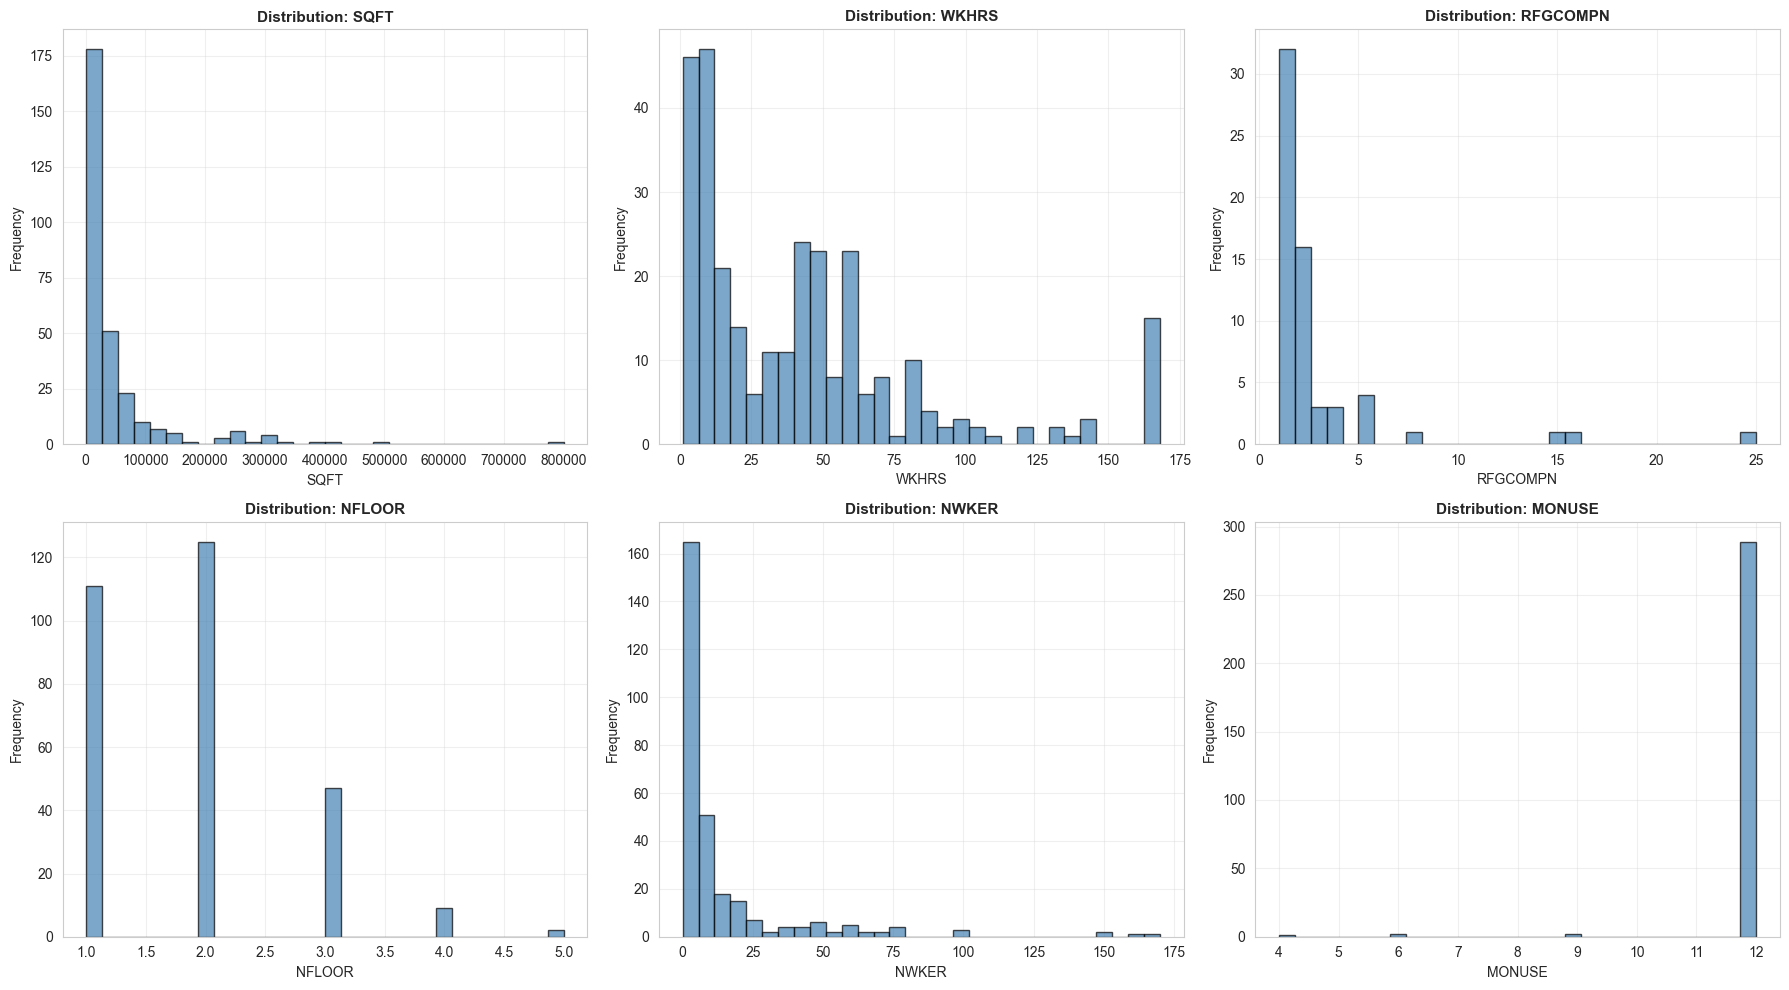

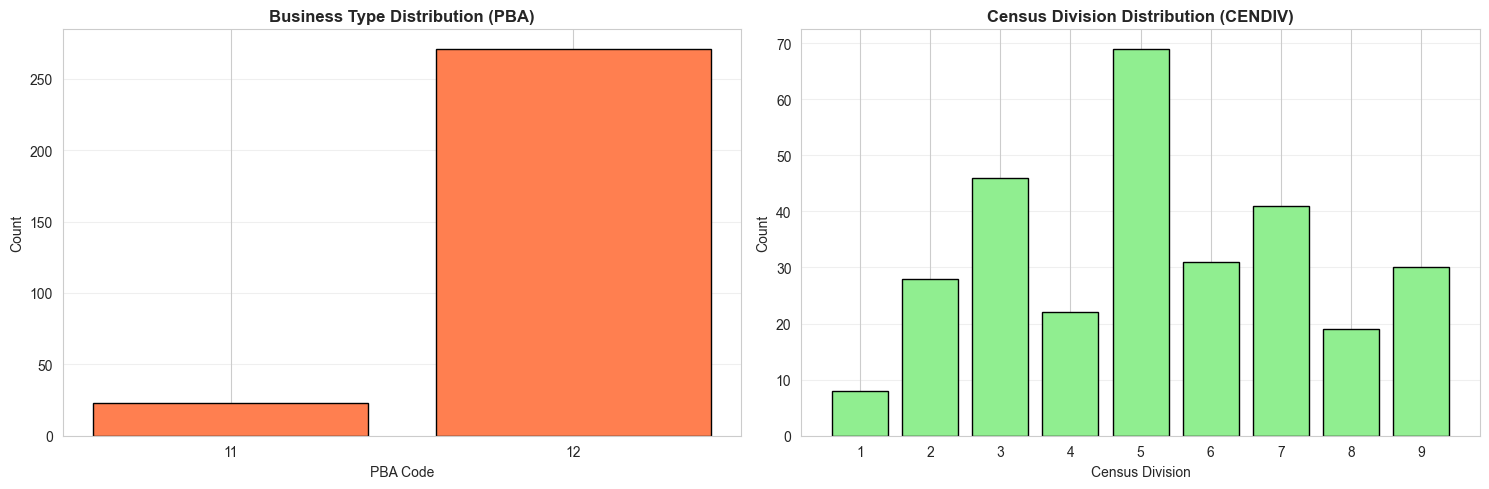

In [ ]:
# Distribution plots for numeric features
numeric_features = ['SQFT', 'WKHRS', 'RFGCOMPN', 'NFLOOR', 'NWKER', 'MONUSE']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, feature in enumerate(numeric_features):
    if feature in df_food.columns:
        axes[i].hist(df_food[feature].dropna(), bins=30, alpha=0.7, color='steelblue', edgecolor='black')
        axes[i].set_title(f'Distribution: {feature}', fontsize=11, fontweight='bold')
        axes[i].set_xlabel(feature)
        axes[i].set_ylabel('Frequency')
        axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Bar charts for categorical features
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# PBA distribution
pba_counts = df_food['PBA'].value_counts().sort_index()
axes[0].bar(pba_counts.index.astype(str), pba_counts.values, color='coral', edgecolor='black')
axes[0].set_title('Business Type Distribution (PBA)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('PBA Code')
axes[0].set_ylabel('Count')
axes[0].grid(True, alpha=0.3, axis='y')

# CENDIV distribution
cendiv_counts = df_food['CENDIV'].value_counts().sort_index()
axes[1].bar(cendiv_counts.index.astype(str), cendiv_counts.values, color='lightgreen', edgecolor='black')
axes[1].set_title('Census Division Distribution (CENDIV)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Census Division')
axes[1].set_ylabel('Count')
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()


### 3.4 Correlation Analysis


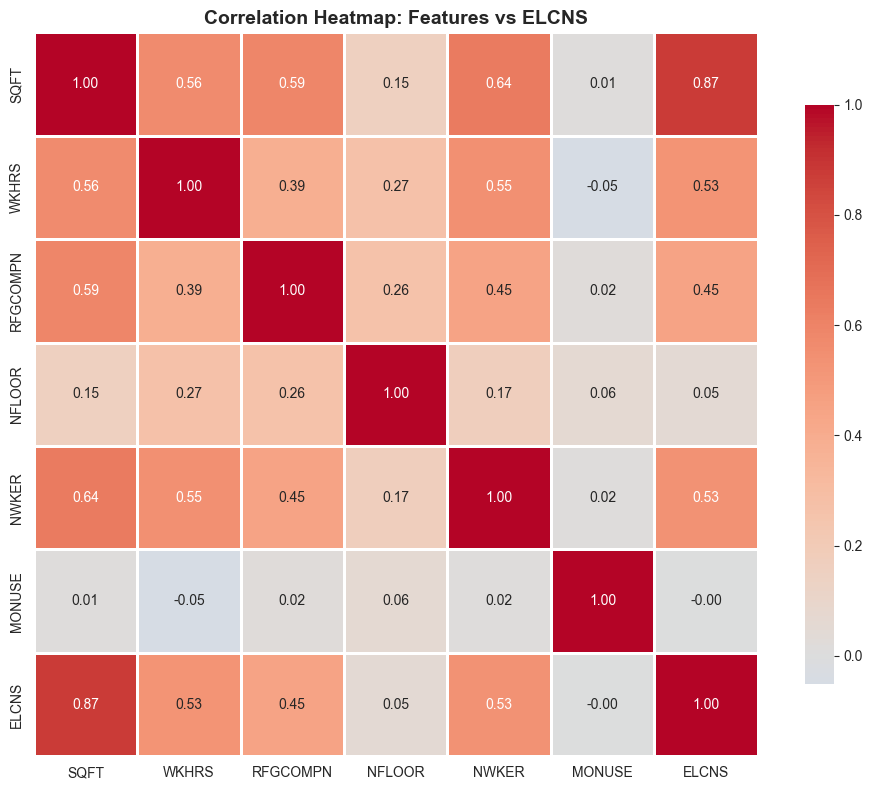

Top 5 features most correlated with ELCNS:
  SQFT        : 0.8745
  NWKER       : 0.5336
  WKHRS       : 0.5309
  RFGCOMPN    : 0.4536
  NFLOOR      : 0.0526


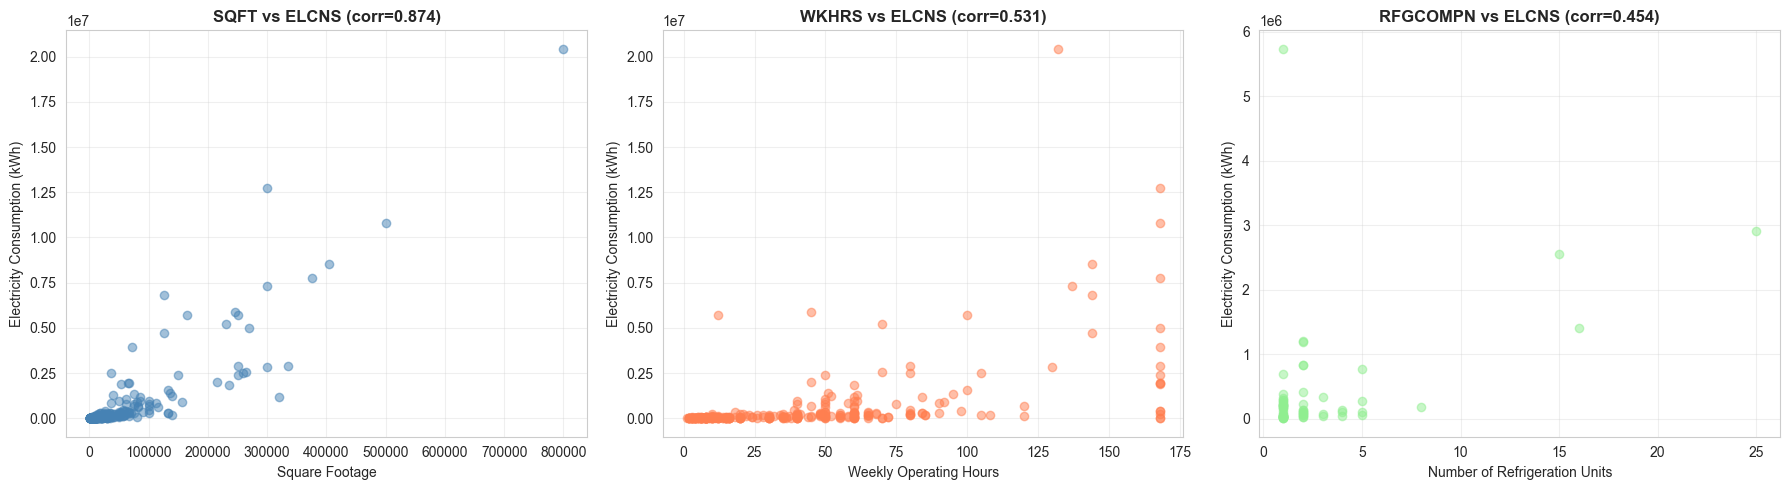

In [ ]:
# Correlation heatmap
numeric_cols = ['SQFT', 'WKHRS', 'RFGCOMPN', 'NFLOOR', 'NWKER', 'MONUSE', 'ELCNS']
corr_matrix = df_food[numeric_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, 
            square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('Correlation Heatmap: Features vs ELCNS', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Top 5 most correlated features with ELCNS
elcns_corr = corr_matrix['ELCNS'].drop('ELCNS').abs().sort_values(ascending=False)
print("Top 5 features most correlated with ELCNS:")
for feature, corr_value in elcns_corr.head(5).items():
    print(f"  {feature:12s}: {corr_value:.4f}")

# Scatter plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# SQFT vs ELCNS
axes[0].scatter(df_food['SQFT'], df_food['ELCNS'], alpha=0.5, color='steelblue')
axes[0].set_title(f'SQFT vs ELCNS (corr={corr_matrix.loc["SQFT", "ELCNS"]:.3f})', fontweight='bold')
axes[0].set_xlabel('Square Footage')
axes[0].set_ylabel('Electricity Consumption (kWh)')
axes[0].grid(True, alpha=0.3)

# WKHRS vs ELCNS
axes[1].scatter(df_food['WKHRS'], df_food['ELCNS'], alpha=0.5, color='coral')
axes[1].set_title(f'WKHRS vs ELCNS (corr={corr_matrix.loc["WKHRS", "ELCNS"]:.3f})', fontweight='bold')
axes[1].set_xlabel('Weekly Operating Hours')
axes[1].set_ylabel('Electricity Consumption (kWh)')
axes[1].grid(True, alpha=0.3)

# RFGCOMPN vs ELCNS
axes[2].scatter(df_food['RFGCOMPN'], df_food['ELCNS'], alpha=0.5, color='lightgreen')
axes[2].set_title(f'RFGCOMPN vs ELCNS (corr={corr_matrix.loc["RFGCOMPN", "ELCNS"]:.3f})', fontweight='bold')
axes[2].set_xlabel('Number of Refrigeration Units')
axes[2].set_ylabel('Electricity Consumption (kWh)')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### 3.5 Business Type Analysis


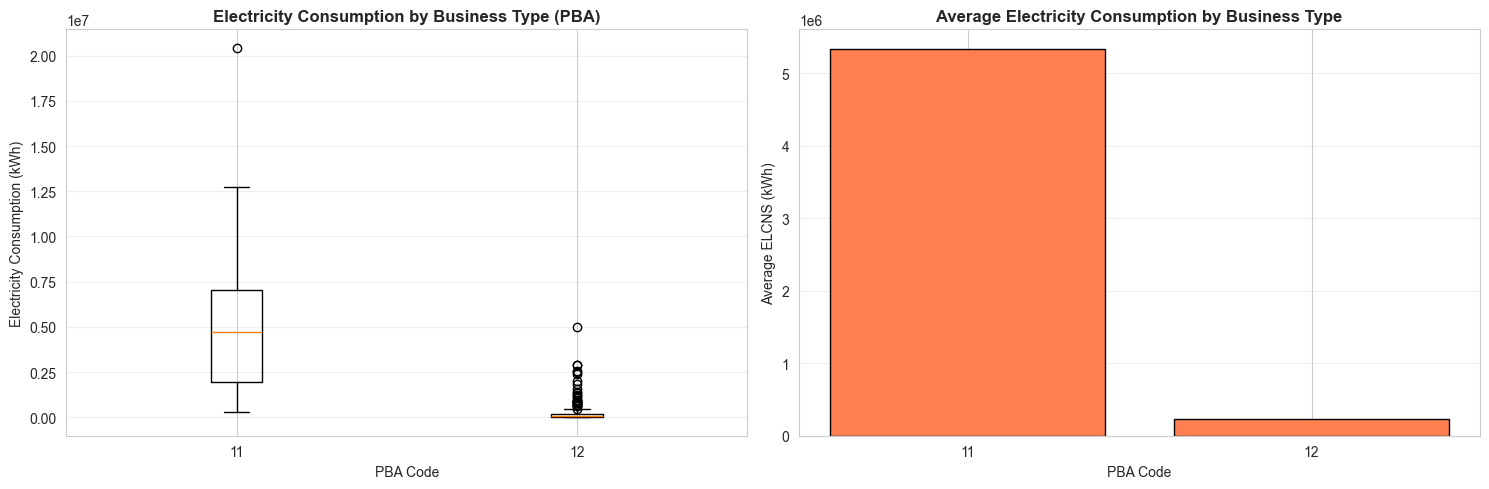

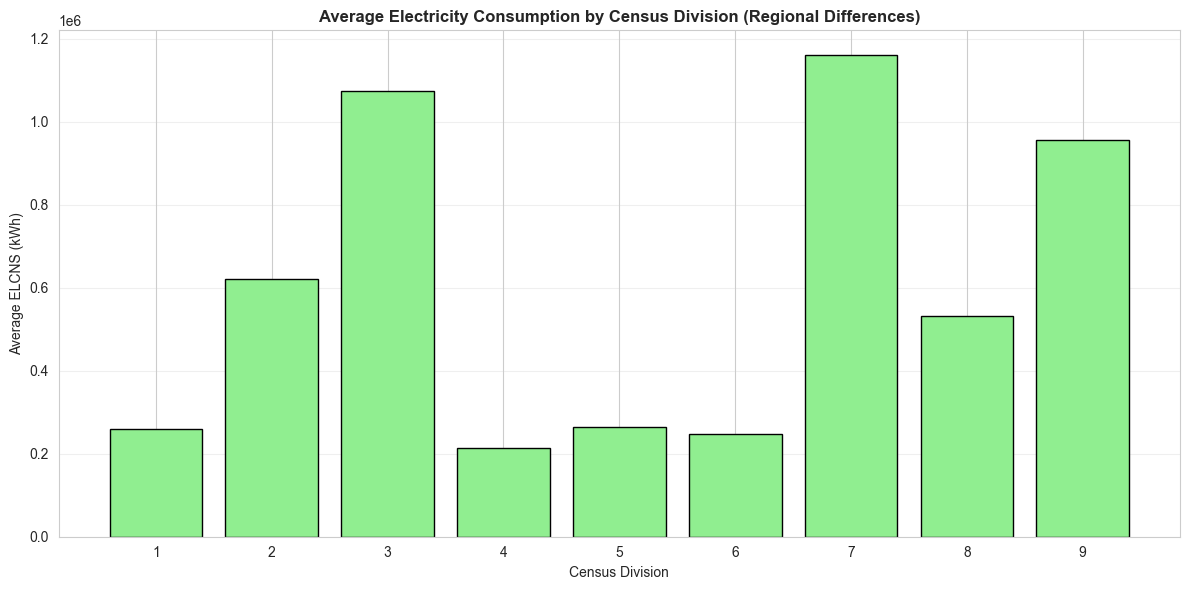

Business Type Summary:
             mean     median           std  count
PBA                                              
11   5.340051e+06  4689836.0  4.640463e+06     23
12   2.326680e+05    55550.0  5.316014e+05    271


In [ ]:
# Box plot: ELCNS by PBA
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Box plot
pba_data = [df_food[df_food['PBA'] == pba]['ELCNS'].values for pba in sorted(df_food['PBA'].unique())]
axes[0].boxplot(pba_data, labels=sorted(df_food['PBA'].unique()))
axes[0].set_title('Electricity Consumption by Business Type (PBA)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('PBA Code')
axes[0].set_ylabel('Electricity Consumption (kWh)')
axes[0].grid(True, alpha=0.3, axis='y')

# Bar chart: Average ELCNS by PBA
avg_elcns_pba = df_food.groupby('PBA')['ELCNS'].mean().sort_index()
axes[1].bar(avg_elcns_pba.index.astype(str), avg_elcns_pba.values, color='coral', edgecolor='black')
axes[1].set_title('Average Electricity Consumption by Business Type', fontsize=12, fontweight='bold')
axes[1].set_xlabel('PBA Code')
axes[1].set_ylabel('Average ELCNS (kWh)')
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

# Average ELCNS by CENDIV
plt.figure(figsize=(12, 6))
avg_elcns_cendiv = df_food.groupby('CENDIV')['ELCNS'].mean().sort_index()
plt.bar(avg_elcns_cendiv.index.astype(str), avg_elcns_cendiv.values, color='lightgreen', edgecolor='black')
plt.title('Average Electricity Consumption by Census Division (Regional Differences)', fontsize=12, fontweight='bold')
plt.xlabel('Census Division')
plt.ylabel('Average ELCNS (kWh)')
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

print("Business Type Summary:")
print(df_food.groupby('PBA')['ELCNS'].agg(['mean', 'median', 'std', 'count']))


### 3.6 Refrigeration Analysis (Critical for our use case)


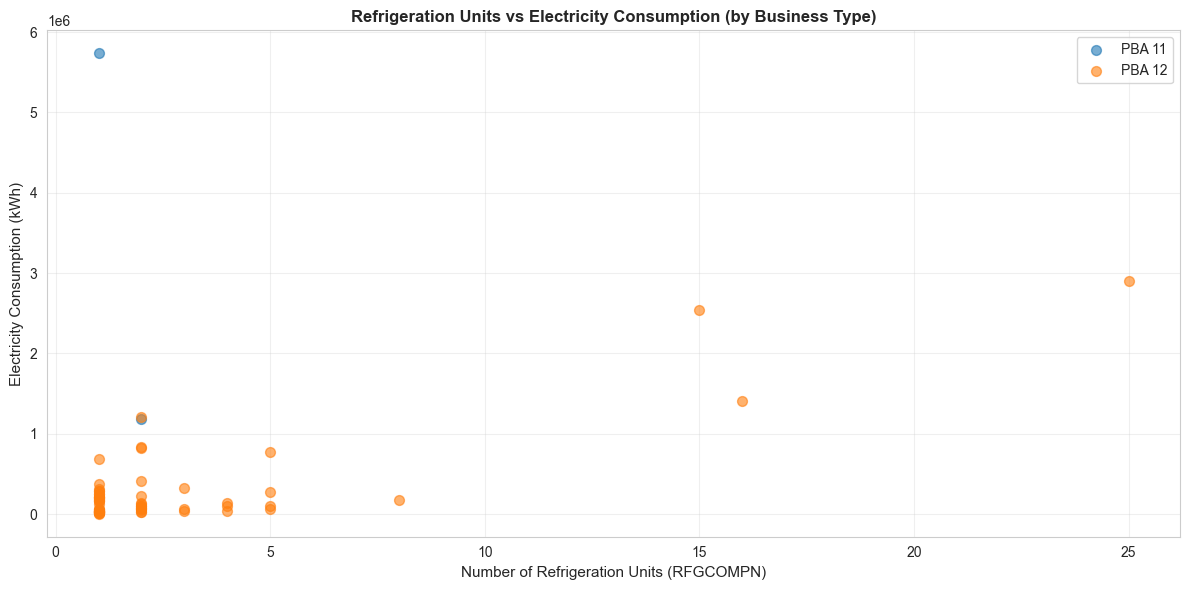

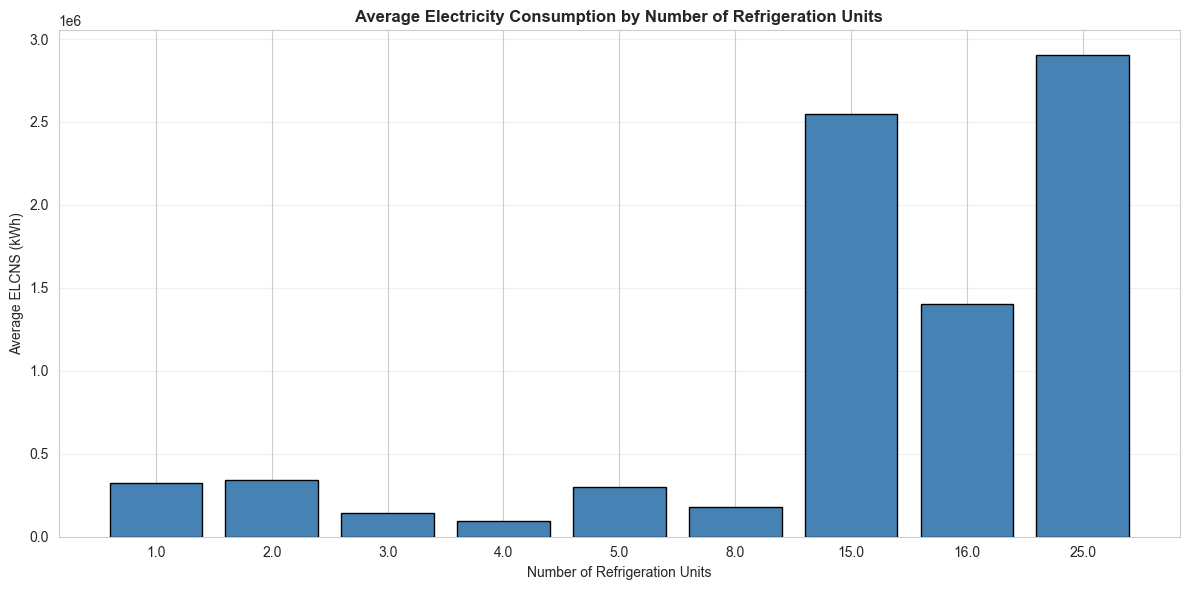


📊 Correlation between RFGCOMPN and ELCNS: 0.4536
This indicates that refrigeration units are moderately correlated with energy consumption.


In [ ]:
# Scatter: RFGCOMPN vs ELCNS colored by PBA
plt.figure(figsize=(12, 6))
for pba in sorted(df_food['PBA'].unique()):
    pba_data = df_food[df_food['PBA'] == pba]
    plt.scatter(pba_data['RFGCOMPN'], pba_data['ELCNS'], 
                alpha=0.6, label=f'PBA {pba}', s=50)
plt.xlabel('Number of Refrigeration Units (RFGCOMPN)', fontsize=11)
plt.ylabel('Electricity Consumption (kWh)', fontsize=11)
plt.title('Refrigeration Units vs Electricity Consumption (by Business Type)', fontsize=12, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Bar chart: Average ELCNS by number of refrigeration units
rfg_elcns = df_food.groupby('RFGCOMPN')['ELCNS'].mean().sort_index()
plt.figure(figsize=(12, 6))
plt.bar(rfg_elcns.index.astype(str), rfg_elcns.values, color='steelblue', edgecolor='black')
plt.title('Average Electricity Consumption by Number of Refrigeration Units', fontsize=12, fontweight='bold')
plt.xlabel('Number of Refrigeration Units')
plt.ylabel('Average ELCNS (kWh)')
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

# Correlation between RFGCOMPN and ELCNS
rfg_corr = df_food['RFGCOMPN'].corr(df_food['ELCNS'])
print(f"\n📊 Correlation between RFGCOMPN and ELCNS: {rfg_corr:.4f}")
print(f"This indicates that refrigeration units are {'strongly' if abs(rfg_corr) > 0.5 else 'moderately' if abs(rfg_corr) > 0.3 else 'weakly'} correlated with energy consumption.")


### 3.7 Operating Hours Analysis


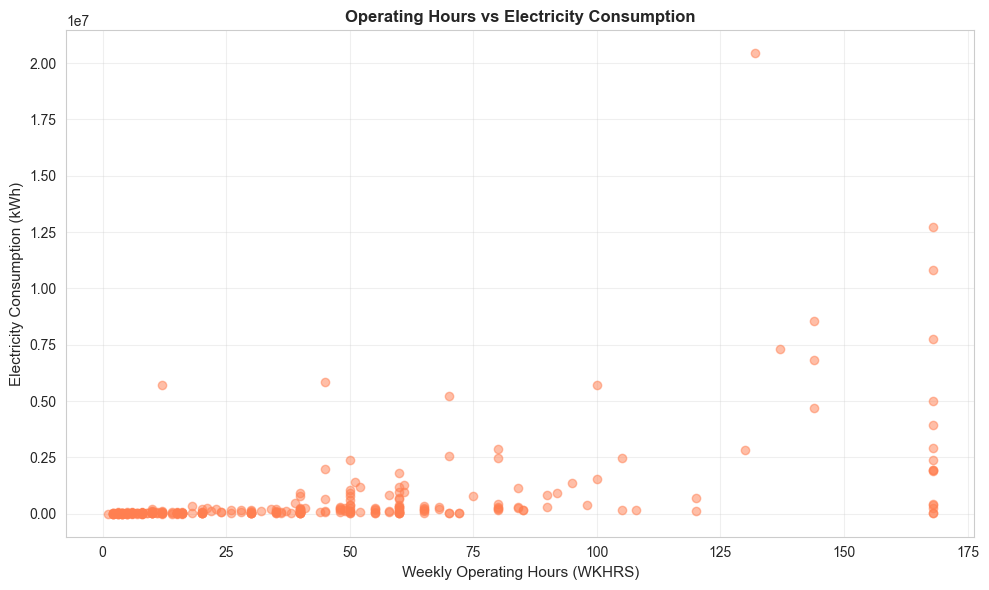

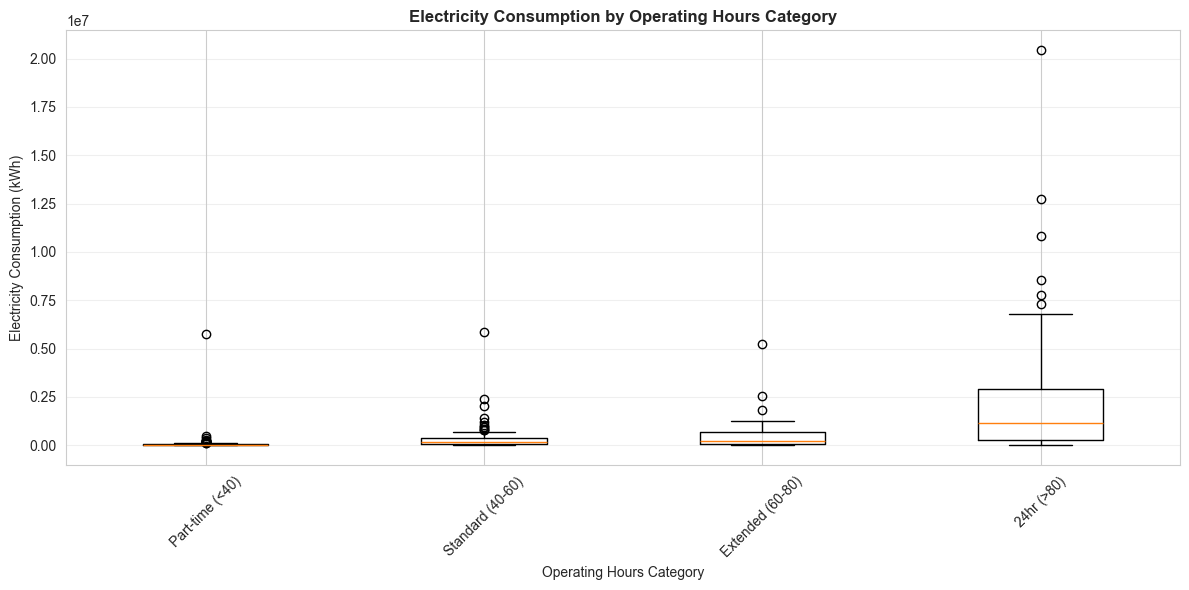


Operating Hours Category Summary:
                          mean     median  count
hours_category                                  
24hr (>80)        2.812698e+06  1159314.0     45
Extended (60-80)  5.699669e+05   231132.0     35
Part-time (<40)   8.753935e+04    32756.0    156
Standard (40-60)  4.430660e+05   159578.5     58


In [ ]:
# Scatter: WKHRS vs ELCNS
plt.figure(figsize=(10, 6))
plt.scatter(df_food['WKHRS'], df_food['ELCNS'], alpha=0.5, color='coral')
plt.xlabel('Weekly Operating Hours (WKHRS)', fontsize=11)
plt.ylabel('Electricity Consumption (kWh)', fontsize=11)
plt.title('Operating Hours vs Electricity Consumption', fontsize=12, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Bin WKHRS into categories
def categorize_hours(wkhrs):
    if wkhrs < 40:
        return 'Part-time (<40)'
    elif wkhrs < 60:
        return 'Standard (40-60)'
    elif wkhrs < 80:
        return 'Extended (60-80)'
    else:
        return '24hr (>80)'

df_food['hours_category'] = df_food['WKHRS'].apply(categorize_hours)

# Box plot: ELCNS by operating hours category
plt.figure(figsize=(12, 6))
categories = ['Part-time (<40)', 'Standard (40-60)', 'Extended (60-80)', '24hr (>80)']
category_data = [df_food[df_food['hours_category'] == cat]['ELCNS'].values for cat in categories]
plt.boxplot(category_data, labels=categories)
plt.title('Electricity Consumption by Operating Hours Category', fontsize=12, fontweight='bold')
plt.xlabel('Operating Hours Category')
plt.ylabel('Electricity Consumption (kWh)')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

print("\nOperating Hours Category Summary:")
print(df_food.groupby('hours_category')['ELCNS'].agg(['mean', 'median', 'count']))


## SECTION 4: Feature Engineering

Create new features to improve model performance and capture important relationships.


### 4.1 Core Engineered Features


In [ ]:
# Create engineered features
df_engineered = df_food.copy()

# Energy intensity (kWh per square foot)
df_engineered['kwh_per_sqft'] = df_engineered['ELCNS'] / df_engineered['SQFT'].replace(0, np.nan)

# Space efficiency (square feet per worker) - handle division by zero
df_engineered['sqft_per_worker'] = df_engineered['SQFT'] / df_engineered['NWKER'].replace(0, np.nan)

# Normalized weekly hours (fraction of full week)
df_engineered['wkhrs_per_week_normalized'] = df_engineered['WKHRS'] / 168

# Annual operating hours approximation
df_engineered['annual_operating_hours'] = df_engineered['WKHRS'] * df_engineered['MONUSE'] * (52/12)

# Refrigeration density (refrigeration units per 1000 sqft)
df_engineered['refrigeration_density'] = (df_engineered['RFGCOMPN'] / df_engineered['SQFT'].replace(0, np.nan)) * 1000

# High refrigeration indicator
median_rfg = df_engineered['RFGCOMPN'].median()
df_engineered['is_high_refrigeration'] = (df_engineered['RFGCOMPN'] > median_rfg).astype(int)

# Extended hours indicator
df_engineered['is_extended_hours'] = (df_engineered['WKHRS'] > 60).astype(int)

# Size category
df_engineered['size_category'] = pd.cut(
    df_engineered['SQFT'], 
    bins=[0, 2000, 10000, float('inf')], 
    labels=['small', 'medium', 'large']
)

print("✅ Core engineered features created")
print(f"\nNew features: kwh_per_sqft, sqft_per_worker, wkhrs_per_week_normalized, annual_operating_hours,")
print(f"              refrigeration_density, is_high_refrigeration, is_extended_hours, size_category")


✅ Core engineered features created

New features: kwh_per_sqft, sqft_per_worker, wkhrs_per_week_normalized, annual_operating_hours,
              refrigeration_density, is_high_refrigeration, is_extended_hours, size_category


### 4.2 Encoding


In [ ]:
# Keep original PBA for reference
df_engineered['pba_original'] = df_engineered['PBA'].copy()

# Label encode categorical features
le_pba = LabelEncoder()
le_cendiv = LabelEncoder()
le_size = LabelEncoder()

df_engineered['pba_encoded'] = le_pba.fit_transform(df_engineered['PBA'].astype(str))
df_engineered['cendiv_encoded'] = le_cendiv.fit_transform(df_engineered['CENDIV'].astype(str))
df_engineered['size_category_encoded'] = le_size.fit_transform(df_engineered['size_category'].astype(str))

print("✅ Categorical features encoded")
print(f"\nPBA encoding: {dict(zip(le_pba.classes_, range(len(le_pba.classes_))))}")
print(f"Size category encoding: {dict(zip(le_size.classes_, range(len(le_size.classes_))))}")


✅ Categorical features encoded

PBA encoding: {'11': 0, '12': 1}
Size category encoding: {'large': 0, 'medium': 1, 'small': 2}


### 4.3 Target Transformation
 vvvvvvc

In [ ]:
# Create log-transformed target (already created in EDA, but ensure it exists)
if 'log_elcns' not in df_engineered.columns:
    df_engineered['log_elcns'] = np.log1p(df_engineered['ELCNS'])

print("✅ Log-transformed target created")
print(f"\nOriginal ELCNS stats:")
print(f"  Mean: {df_engineered['ELCNS'].mean():,.2f}")
print(f"  Std:  {df_engineered['ELCNS'].std():,.2f}")
print(f"\nLog-transformed ELCNS stats:")
print(f"  Mean: {df_engineered['log_elcns'].mean():.2f}")
print(f"  Std:  {df_engineered['log_elcns'].std():.2f}")


✅ Log-transformed target created

Original ELCNS stats:
  Mean: 632,225.22
  Std:  1,940,299.40

Log-transformed ELCNS stats:
  Mean: 11.44
  Std:  1.83


### 4.4 Handle Outliers


In [ ]:
# Remove extreme outliers
initial_rows = len(df_engineered)

# Remove rows where ELCNS > 99th percentile
elcns_99th = df_engineered['ELCNS'].quantile(0.99)
df_engineered = df_engineered[df_engineered['ELCNS'] <= elcns_99th].copy()

# Remove rows where SQFT < 100 (data errors)
df_engineered = df_engineered[df_engineered['SQFT'] >= 100].copy()

rows_removed = initial_rows - len(df_engineered)
print(f"Rows removed: {rows_removed} ({rows_removed/initial_rows*100:.2f}%)")
print(f"Remaining rows: {len(df_engineered)}")
print(f"\nRemoved:")
print(f"  - ELCNS > 99th percentile ({elcns_99th:,.0f} kWh)")
print(f"  - SQFT < 100 sqft")


Rows removed: 3 (1.02%)
Remaining rows: 291

Removed:
  - ELCNS > 99th percentile (8,715,130 kWh)
  - SQFT < 100 sqft


### 4.5 Handle Missing Values


In [ ]:
# Fill missing values with median for numeric columns
numeric_cols_to_fill = ['SQFT', 'WKHRS', 'RFGCOMPN', 'NFLOOR', 'NWKER', 'MONUSE', 
                        'kwh_per_sqft', 'sqft_per_worker', 'wkhrs_per_week_normalized',
                        'annual_operating_hours', 'refrigeration_density']

for col in numeric_cols_to_fill:
    if col in df_engineered.columns:
        median_val = df_engineered[col].median()
        df_engineered[col].fillna(median_val, inplace=True)
        print(f"Filled {col} missing values with median: {median_val:.2f}")

print("\n✅ Missing values handled")
print(f"\nRemaining missing values per column:")
missing_after = df_engineered.isnull().sum()
print(missing_after[missing_after > 0] if missing_after.sum() > 0 else "None")


Filled SQFT missing values with median: 20000.00
Filled WKHRS missing values with median: 35.00
Filled RFGCOMPN missing values with median: 1.00
Filled NFLOOR missing values with median: 2.00
Filled NWKER missing values with median: 4.00
Filled MONUSE missing values with median: 12.00
Filled kwh_per_sqft missing values with median: 4.91
Filled sqft_per_worker missing values with median: 3538.46
Filled wkhrs_per_week_normalized missing values with median: 0.21
Filled annual_operating_hours missing values with median: 1820.00
Filled refrigeration_density missing values with median: 0.07

✅ Missing values handled

Remaining missing values per column:
None


### 4.6 Final Feature List


In [ ]:
# Define features to use in model (exclude target and original categoricals)
exclude_features = ['ELCNS', 'log_elcns', 'pba_original', 'PBA', 'CENDIV', 'size_category', 'hours_category']

feature_columns = [col for col in df_engineered.columns if col not in exclude_features]

print("Features going into model:")
for i, feat in enumerate(feature_columns, 1):
    print(f"  {i:2d}. {feat}")

print(f"\nTotal features: {len(feature_columns)}")
print(f"Final dataset shape: {df_engineered.shape}")
print(f"Final dataset memory usage: {df_engineered.memory_usage(deep=True).sum() / 1024**2:.2f} MB")


Features going into model:
   1. SQFT
   2. WKHRS
   3. RFGCOMPN
   4. NFLOOR
   5. NWKER
   6. MONUSE
   7. YRCONC
   8. kwh_per_sqft
   9. sqft_per_worker
  10. wkhrs_per_week_normalized
  11. annual_operating_hours
  12. refrigeration_density
  13. is_high_refrigeration
  14. is_extended_hours
  15. pba_encoded
  16. cendiv_encoded
  17. size_category_encoded

Total features: 17
Final dataset shape: (291, 24)
Final dataset memory usage: 0.07 MB


## SECTION 5: Model Development

Train multiple models and compare their performance on both raw and log-transformed targets.


### 5.1 Train/Test Split


In [ ]:
# Prepare features and targets
X = df_engineered[feature_columns].copy()
y = df_engineered['ELCNS'].copy()  # Raw target
y_log = df_engineered['log_elcns'].copy()  # Log-transformed target

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X_train_log, X_test_log, y_train_log, y_test_log = train_test_split(
    X, y_log, test_size=0.2, random_state=42
)

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_log_scaled = scaler.fit_transform(X_train_log)
X_test_log_scaled = scaler.transform(X_test_log)

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Test set size: {X_test.shape[0]} samples")
print(f"Number of features: {X_train.shape[1]}")
print("\n✅ Data split and scaled successfully")


Training set size: 232 samples
Test set size: 59 samples
Number of features: 17

✅ Data split and scaled successfully


### 5.2 Train Models on RAW Target


In [ ]:
# Define models
models_raw = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=200, random_state=42),
    'XGBoost': xgb.XGBRegressor(n_estimators=200, learning_rate=0.1, random_state=42, n_jobs=-1)
}

# Train and evaluate models
results_raw = {}

for name, model in models_raw.items():
    print(f"\n{'='*60}")
    print(f"Training {name}...")
    print('='*60)
    
    # Train
    model.fit(X_train_scaled, y_train)
    
    # Predictions
    y_train_pred = model.predict(X_train_scaled)
    y_test_pred = model.predict(X_test_scaled)
    
    # Metrics
    train_r2 = r2_score(y_train, y_train_pred)
    test_r2 = r2_score(y_test, y_test_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
    mae = mean_absolute_error(y_test, y_test_pred)
    mape = np.mean(np.abs((y_test - y_test_pred) / y_test)) * 100
    
    # Cross-validation
    cv_scores = cross_val_score(model, X_train_scaled, y_train, cv=5, scoring='r2', n_jobs=-1)
    cv_mean = cv_scores.mean()
    cv_std = cv_scores.std()
    
    results_raw[name] = {
        'train_r2': train_r2,
        'test_r2': test_r2,
        'rmse': rmse,
        'mae': mae,
        'mape': mape,
        'cv_r2_mean': cv_mean,
        'cv_r2_std': cv_std,
        'model': model
    }
    
    print(f"Train R²:     {train_r2:.4f}")
    print(f"Test R²:      {test_r2:.4f}")
    print(f"RMSE:         {rmse:,.2f}")
    print(f"MAE:          {mae:,.2f}")
    print(f"MAPE:         {mape:.2f}%")
    print(f"CV R²:        {cv_mean:.4f} ± {cv_std:.4f}")

print("\n✅ All models trained on RAW target")



Training Linear Regression...
Train R²:     0.8595
Test R²:      0.8352
RMSE:         665,101.14
MAE:          381,711.96
MAPE:         1364.47%
CV R²:        0.5948 ± 0.2931

Training Random Forest...
Train R²:     0.9744
Test R²:      0.9333
RMSE:         423,154.16
MAE:          147,826.87
MAPE:         33.54%
CV R²:        0.7700 ± 0.1463

Training Gradient Boosting...
Train R²:     1.0000
Test R²:      0.9395
RMSE:         403,030.38
MAE:          149,872.01
MAPE:         36.20%
CV R²:        0.8275 ± 0.0610

Training XGBoost...
Train R²:     1.0000
Test R²:      0.9559
RMSE:         343,861.83
MAE:          109,381.77
MAPE:         22.61%
CV R²:        0.6875 ± 0.2057

✅ All models trained on RAW target


In [ ]:
# Define models for log-transformed target
models_log = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=200, random_state=42),
    'XGBoost': xgb.XGBRegressor(n_estimators=200, learning_rate=0.1, random_state=42, n_jobs=-1)
}

# Train and evaluate models
results_log = {}

for name, model in models_log.items():
    print(f"\n{'='*60}")
    print(f"Training {name} (Log Target)...")
    print('='*60)
    
    # Train
    model.fit(X_train_log_scaled, y_train_log)
    
    # Predictions (inverse transform)
    y_train_pred_log = np.expm1(model.predict(X_train_log_scaled))
    y_test_pred_log = np.expm1(model.predict(X_test_log_scaled))
    
    # Metrics (on original scale)
    train_r2 = r2_score(y_train, y_train_pred_log)
    test_r2 = r2_score(y_test, y_test_pred_log)
    rmse = np.sqrt(mean_squared_error(y_test, y_test_pred_log))
    mae = mean_absolute_error(y_test, y_test_pred_log)
    mape = np.mean(np.abs((y_test - y_test_pred_log) / y_test)) * 100
    
    # Cross-validation (on original scale)
    cv_scores = []
    from sklearn.model_selection import KFold
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    for train_idx, val_idx in kf.split(X_train_log_scaled):
        X_tr, X_val = X_train_log_scaled[train_idx], X_train_log_scaled[val_idx]
        y_tr, y_val = y_train_log.iloc[train_idx], y_train_log.iloc[val_idx]
        model.fit(X_tr, y_tr)
        y_val_pred_log = np.expm1(model.predict(X_val))
        cv_scores.append(r2_score(y_train.iloc[val_idx], y_val_pred_log))
    
    cv_mean = np.mean(cv_scores)
    cv_std = np.std(cv_scores)
    
    results_log[name] = {
        'train_r2': train_r2,
        'test_r2': test_r2,
        'rmse': rmse,
        'mae': mae,
        'mape': mape,
        'cv_r2_mean': cv_mean,
        'cv_r2_std': cv_std,
        'model': model
    }
    
    print(f"Train R²:     {train_r2:.4f}")
    print(f"Test R²:      {test_r2:.4f}")
    print(f"RMSE:         {rmse:,.2f}")
    print(f"MAE:          {mae:,.2f}")
    print(f"MAPE:         {mape:.2f}%")
    print(f"CV R²:        {cv_mean:.4f} ± {cv_std:.4f}")

print("\n✅ All models trained on LOG-TRANSFORMED target")



Training Linear Regression (Log Target)...
Train R²:     -4.2864
Test R²:      -0.4346
RMSE:         1,962,044.15
MAE:          487,412.45
MAPE:         55.89%
CV R²:        -18.7543 ± 21.9983

Training Random Forest (Log Target)...
Train R²:     0.9521
Test R²:      0.8784
RMSE:         571,190.22
MAE:          169,636.33
MAPE:         19.21%
CV R²:        0.8114 ± 0.0962

Training Gradient Boosting (Log Target)...
Train R²:     0.9997
Test R²:      0.9830
RMSE:         213,365.93
MAE:          72,175.49
MAPE:         14.52%
CV R²:        0.8683 ± 0.1255

Training XGBoost (Log Target)...
Train R²:     1.0000
Test R²:      0.8989
RMSE:         520,849.68
MAE:          141,868.17
MAPE:         20.18%
CV R²:        0.7579 ± 0.1396

✅ All models trained on LOG-TRANSFORMED target


Model Comparison Summary:
                  Model Target   Test_R2        MAPE         RMSE  CV_R2_Mean  CV_R2_Std
Gradient Boosting (Log)    Log  0.983035   14.516639 2.133659e+05    0.868311   0.125524
          XGBoost (Raw)    Raw  0.955938   22.612945 3.438618e+05    0.687461   0.205684
Gradient Boosting (Raw)    Raw  0.939469   36.196570 4.030304e+05    0.827528   0.061015
    Random Forest (Raw)    Raw  0.933274   33.543095 4.231542e+05    0.770028   0.146348
          XGBoost (Log)    Log  0.898906   20.178528 5.208497e+05    0.757873   0.139597
    Random Forest (Log)    Log  0.878420   19.206837 5.711902e+05    0.811423   0.096226
Linear Regression (Raw)    Raw  0.835155 1364.469264 6.651011e+05    0.594846   0.293050
Linear Regression (Log)    Log -0.434557   55.886197 1.962044e+06  -18.754330  21.998303


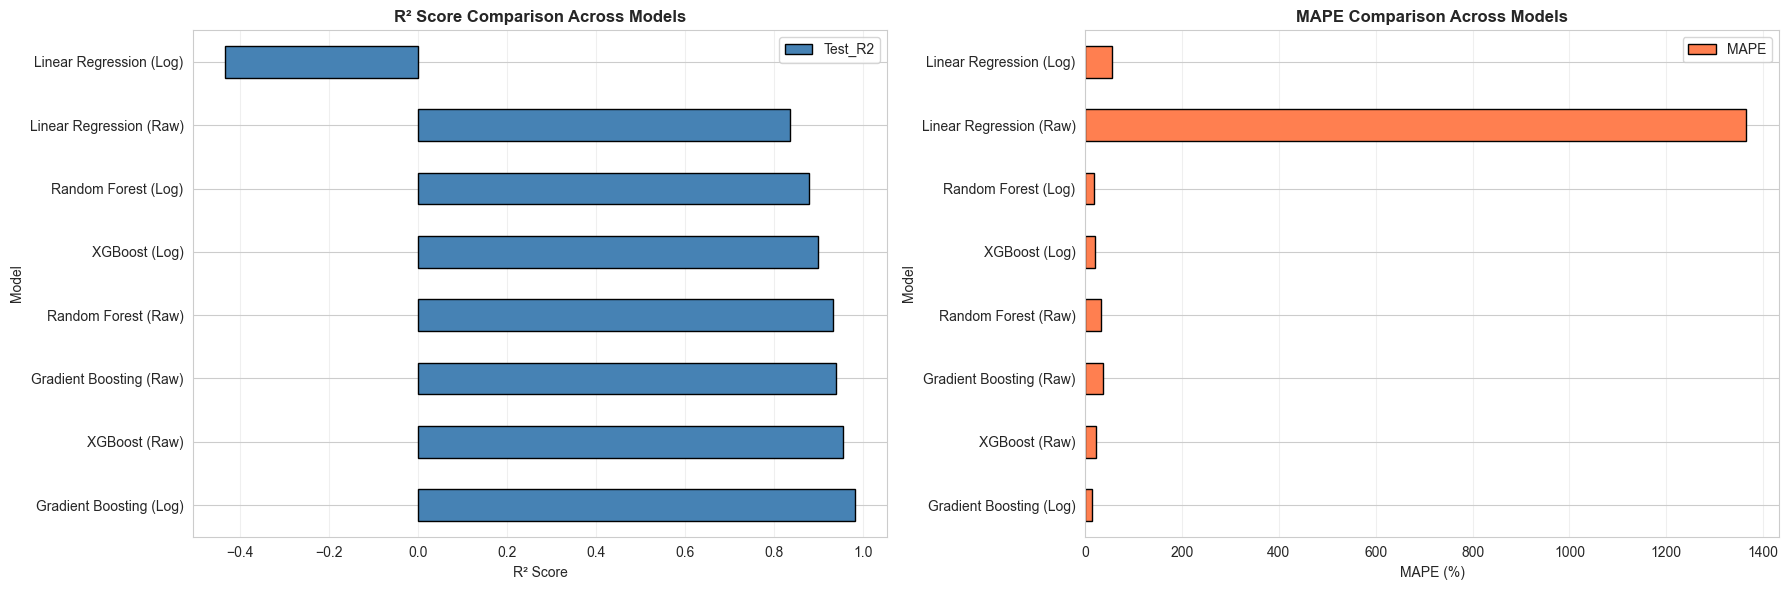


🏆 Best Model: Gradient Boosting (Log)
   Test R²: 0.9830
   MAPE: 14.52%


In [ ]:
# Create comparison DataFrame
comparison_data = []

for name in models_raw.keys():
    comparison_data.append({
        'Model': f"{name} (Raw)",
        'Target': 'Raw',
        'Test_R2': results_raw[name]['test_r2'],
        'MAPE': results_raw[name]['mape'],
        'RMSE': results_raw[name]['rmse'],
        'CV_R2_Mean': results_raw[name]['cv_r2_mean'],
        'CV_R2_Std': results_raw[name]['cv_r2_std']
    })
    
    comparison_data.append({
        'Model': f"{name} (Log)",
        'Target': 'Log',
        'Test_R2': results_log[name]['test_r2'],
        'MAPE': results_log[name]['mape'],
        'RMSE': results_log[name]['rmse'],
        'CV_R2_Mean': results_log[name]['cv_r2_mean'],
        'CV_R2_Std': results_log[name]['cv_r2_std']
    })

comparison_df = pd.DataFrame(comparison_data)
comparison_df = comparison_df.sort_values('Test_R2', ascending=False)

print("Model Comparison Summary:")
print("="*80)
print(comparison_df.to_string(index=False))
print("="*80)

# Visualizations
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# R² comparison
comparison_df.plot(x='Model', y='Test_R2', kind='barh', ax=axes[0], color='steelblue', edgecolor='black')
axes[0].set_title('R² Score Comparison Across Models', fontsize=12, fontweight='bold')
axes[0].set_xlabel('R² Score')
axes[0].set_ylabel('Model')
axes[0].grid(True, alpha=0.3, axis='x')

# MAPE comparison
comparison_df.plot(x='Model', y='MAPE', kind='barh', ax=axes[1], color='coral', edgecolor='black')
axes[1].set_title('MAPE Comparison Across Models', fontsize=12, fontweight='bold')
axes[1].set_xlabel('MAPE (%)')
axes[1].set_ylabel('Model')
axes[1].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.show()

# Find best model
best_model_row = comparison_df.iloc[0]
best_model_name = best_model_row['Model']
best_r2 = best_model_row['Test_R2']
best_mape = best_model_row['MAPE']

print(f"\n🏆 Best Model: {best_model_name}")
print(f"   Test R²: {best_r2:.4f}")
print(f"   MAPE: {best_mape:.2f}%")


### 5.5 Best Model Analysis


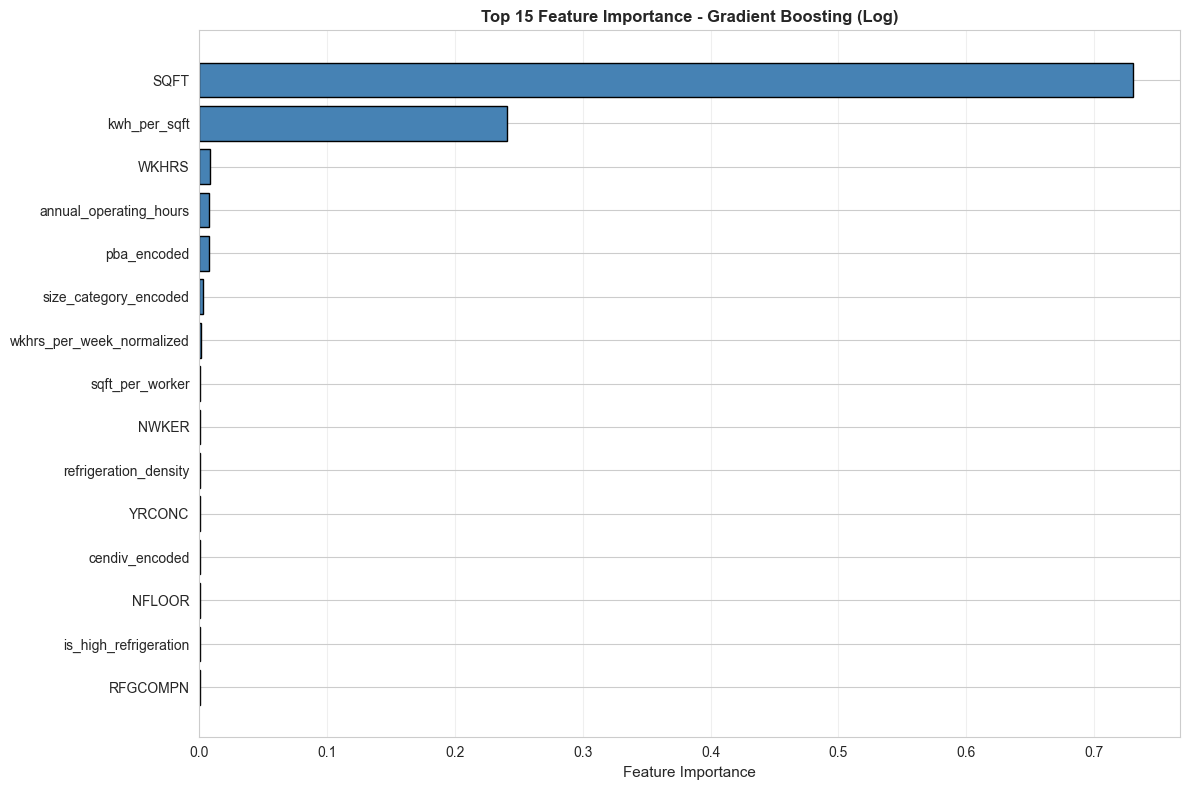


Top 15 Most Important Features:
                  feature  importance
                     SQFT    0.730938
             kwh_per_sqft    0.240439
                    WKHRS    0.008134
   annual_operating_hours    0.007620
              pba_encoded    0.007330
    size_category_encoded    0.002396
wkhrs_per_week_normalized    0.000974
          sqft_per_worker    0.000746
                    NWKER    0.000595
    refrigeration_density    0.000251
                   YRCONC    0.000177
           cendiv_encoded    0.000160
                   NFLOOR    0.000131
    is_high_refrigeration    0.000082
                 RFGCOMPN    0.000022


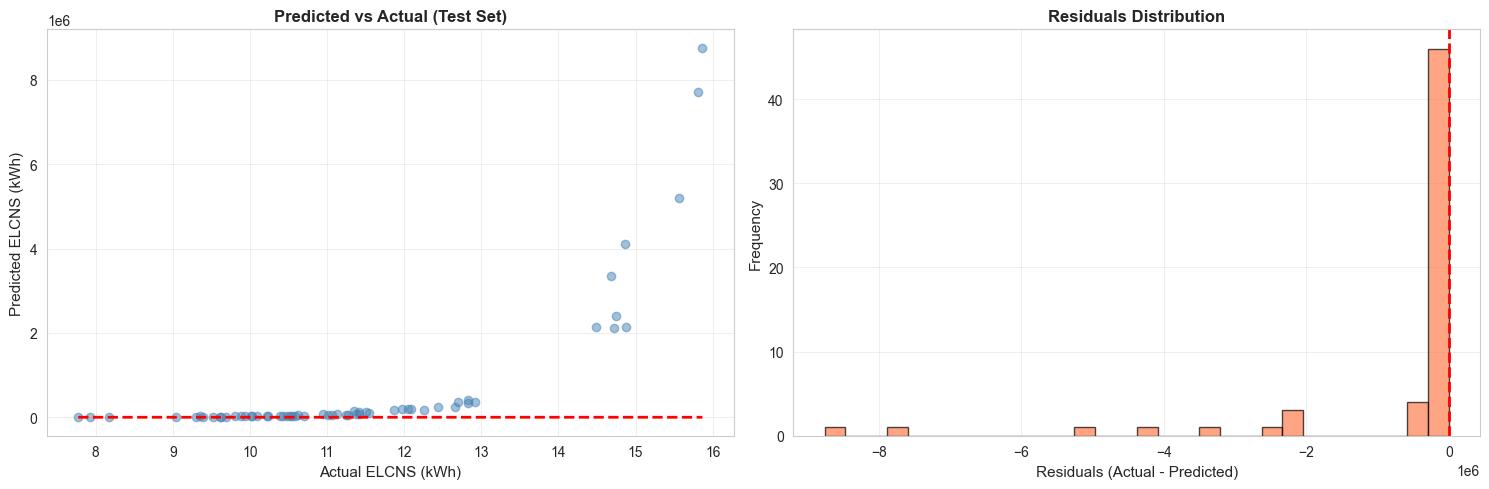


Residuals Statistics:
  Mean: -719299.24
  Std:  1767654.13
  Min:  -8760844.34
  Max:  -3338.79


In [ ]:
# Determine which model to analyze
use_log = 'Log' in best_model_name
model_name_base = best_model_name.split(' (')[0]

if use_log:
    best_model_obj = results_log[model_name_base]['model']
    X_train_used = X_train_log_scaled
    X_test_used = X_test_log_scaled
    y_train_used = y_train_log
    y_test_used = y_test_log
    y_train_pred = np.expm1(best_model_obj.predict(X_train_used))
    y_test_pred = np.expm1(best_model_obj.predict(X_test_used))
else:
    best_model_obj = results_raw[model_name_base]['model']
    X_train_used = X_train_scaled
    X_test_used = X_test_scaled
    y_train_used = y_train
    y_test_used = y_test
    y_train_pred = best_model_obj.predict(X_train_used)
    y_test_pred = best_model_obj.predict(X_test_used)

# Feature importance (if available)
if hasattr(best_model_obj, 'feature_importances_'):
    feature_importance = pd.DataFrame({
        'feature': feature_columns,
        'importance': best_model_obj.feature_importances_
    }).sort_values('importance', ascending=False)
    
    plt.figure(figsize=(12, 8))
    top_features = feature_importance.head(15)
    plt.barh(range(len(top_features)), top_features['importance'], color='steelblue', edgecolor='black')
    plt.yticks(range(len(top_features)), top_features['feature'])
    plt.xlabel('Feature Importance', fontsize=11)
    plt.title(f'Top 15 Feature Importance - {best_model_name}', fontsize=12, fontweight='bold')
    plt.gca().invert_yaxis()
    plt.grid(True, alpha=0.3, axis='x')
    plt.tight_layout()
    plt.show()
    
    print("\nTop 15 Most Important Features:")
    print(top_features.to_string(index=False))
else:
    print("Feature importance not available for this model type")

# Residuals plot
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Predicted vs Actual
axes[0].scatter(y_test_used, y_test_pred, alpha=0.5, color='steelblue')
axes[0].plot([y_test_used.min(), y_test_used.max()], 
            [y_test_used.min(), y_test_used.max()], 'r--', lw=2)
axes[0].set_xlabel('Actual ELCNS (kWh)', fontsize=11)
axes[0].set_ylabel('Predicted ELCNS (kWh)', fontsize=11)
axes[0].set_title('Predicted vs Actual (Test Set)', fontsize=12, fontweight='bold')
axes[0].grid(True, alpha=0.3)

# Residuals distribution
residuals = y_test_used - y_test_pred
axes[1].hist(residuals, bins=30, alpha=0.7, color='coral', edgecolor='black')
axes[1].axvline(x=0, color='red', linestyle='--', linewidth=2)
axes[1].set_xlabel('Residuals (Actual - Predicted)', fontsize=11)
axes[1].set_ylabel('Frequency', fontsize=11)
axes[1].set_title('Residuals Distribution', fontsize=12, fontweight='bold')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nResiduals Statistics:")
print(f"  Mean: {residuals.mean():.2f}")
print(f"  Std:  {residuals.std():.2f}")
print(f"  Min:  {residuals.min():.2f}")
print(f"  Max:  {residuals.max():.2f}")


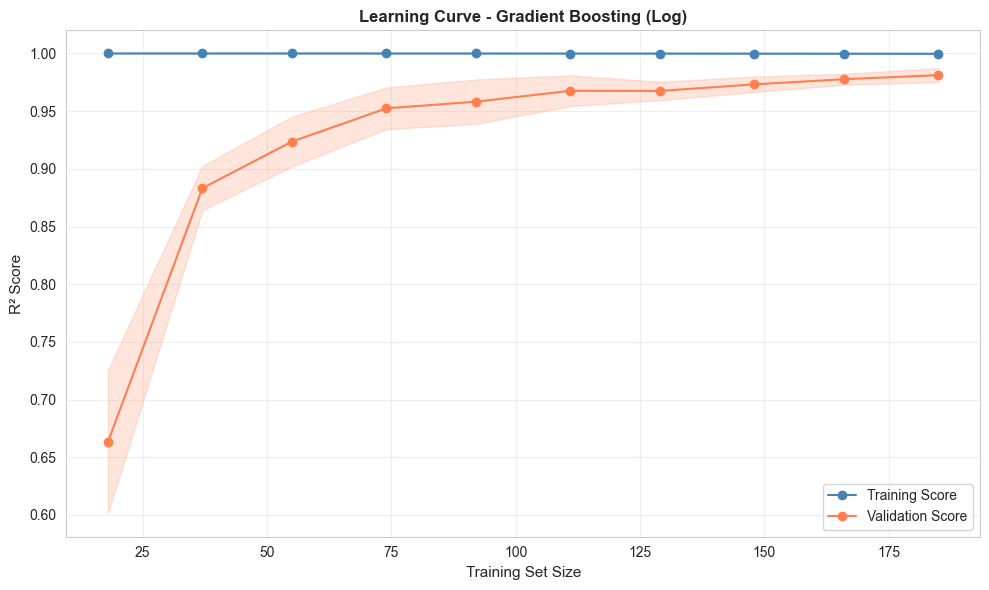

In [ ]:
# Learning curve
from sklearn.model_selection import learning_curve

train_sizes, train_scores, val_scores = learning_curve(
    best_model_obj, X_train_used, y_train_used if not use_log else y_train_log,
    cv=5, n_jobs=-1, train_sizes=np.linspace(0.1, 1.0, 10), scoring='r2'
)

train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)
val_mean = val_scores.mean(axis=1)
val_std = val_scores.std(axis=1)

plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_mean, 'o-', color='steelblue', label='Training Score')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.2, color='steelblue')
plt.plot(train_sizes, val_mean, 'o-', color='coral', label='Validation Score')
plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.2, color='coral')
plt.xlabel('Training Set Size', fontsize=11)
plt.ylabel('R² Score', fontsize=11)
plt.title(f'Learning Curve - {best_model_name}', fontsize=12, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### 5.6 Hyperparameter Tuning (for best model only)


In [ ]:
# Hyperparameter tuning for Random Forest or XGBoost
if model_name_base in ['Random Forest', 'XGBoost']:
    print(f"Performing hyperparameter tuning for {model_name_base}...")
    
    if model_name_base == 'Random Forest':
        param_grid = {
            'n_estimators': [100, 200, 300],
            'max_depth': [10, 20, 30, None],
            'min_samples_split': [2, 5, 10],
            'min_samples_leaf': [1, 2, 4]
        }
        base_model = RandomForestRegressor(random_state=42, n_jobs=-1)
        
    elif model_name_base == 'XGBoost':
        param_grid = {
            'n_estimators': [100, 200, 300],
            'max_depth': [3, 5, 7],
            'learning_rate': [0.05, 0.1, 0.15],
            'subsample': [0.8, 0.9, 1.0]
        }
        base_model = xgb.XGBRegressor(random_state=42, n_jobs=-1)
    
    # Use RandomizedSearchCV for faster search (10 combinations)
    random_search = RandomizedSearchCV(
        base_model, param_grid, n_iter=10, cv=5, 
        scoring='r2', n_jobs=-1, random_state=42, verbose=1
    )
    
    random_search.fit(X_train_used, y_train_used if not use_log else y_train_log)
    
    print(f"\nBest parameters:")
    for param, value in random_search.best_params_.items():
        print(f"  {param}: {value}")
    
    # Retrain with best parameters
    best_tuned_model = random_search.best_estimator_
    
    # Evaluate tuned model
    if use_log:
        y_test_pred_tuned = np.expm1(best_tuned_model.predict(X_test_used))
    else:
        y_test_pred_tuned = best_tuned_model.predict(X_test_used)
    
    tuned_r2 = r2_score(y_test, y_test_pred_tuned)
    tuned_mape = np.mean(np.abs((y_test - y_test_pred_tuned) / y_test)) * 100
    
    print(f"\nTuned Model Performance:")
    print(f"  Test R²: {tuned_r2:.4f}")
    print(f"  MAPE: {tuned_mape:.2f}%")
    
    # Update best model if tuned version is better
    if tuned_r2 > best_r2:
        print(f"\n✅ Tuned model improved performance!")
        best_model_obj = best_tuned_model
        best_r2 = tuned_r2
        best_mape = tuned_mape
    else:
        print(f"\n⚠️ Tuned model did not improve performance. Using original.")
else:
    print(f"Hyperparameter tuning not performed for {model_name_base} (Linear Regression or Gradient Boosting)")


Hyperparameter tuning not performed for Gradient Boosting (Linear Regression or Gradient Boosting)


## SECTION 6: African SME Adaptation

Create a prediction function that maps African SME inputs to CBECS features and applies climate adjustments.


In [ ]:
def predict_african_sme_consumption(
    business_type: str,  # 'butchery', 'grocery', 'mini_supermarket'
    sqft: float,         # approximate floor area in sqft (or convert from m²)
    operating_hours_per_week: float,  # weekly operating hours
    num_refrigeration_units: int,     # fridges + freezers combined
    num_workers: int = 5,             # estimated staff
    months_per_year: int = 12,
    location: str = "Lagos, Nigeria"  # for climate adjustment
) -> dict:
    """
    Maps African SME inputs to CBECS features and returns consumption prediction.
    
    Args:
        business_type: Type of business ('butchery', 'grocery', 'mini_supermarket')
        sqft: Floor area in square feet (convert from m²: sqft = m² * 10.764)
        operating_hours_per_week: Weekly operating hours
        num_refrigeration_units: Total number of refrigeration/freezer units
        num_workers: Number of employees
        months_per_year: Months the business operates per year
        location: City/location string for climate adjustment
    
    Returns:
        Dictionary with estimated consumption and metadata
    """
    
    # Business type mapping to CBECS PBA codes
    # PBA 11 = Food Sales (closer to grocery/supermarket)
    # PBA 12 = Food Service (closer to restaurants, but we'll use 11 for retail)
    business_type_mapping = {
        'butchery': 11,
        'grocery': 11,
        'mini_supermarket': 11
    }
    
    pba_code = business_type_mapping.get(business_type.lower(), 11)
    
    # Climate adjustment factors for Sub-Saharan Africa
    # African refrigeration works ~20-35% harder due to heat/humidity
    climate_zones = {
        'lagos': 1.35,
        'accra': 1.30,
        'nairobi': 1.20,
        'kampala': 1.25,
        'johannesburg': 1.18,
        'dar es salaam': 1.35,
        'kinshasa': 1.35,
        'abidjan': 1.30
    }
    
    # Find climate factor from location string
    location_lower = location.lower()
    climate_factor = 1.20  # default
    for city, factor in climate_zones.items():
        if city in location_lower:
            climate_factor = factor
            break
    
    # Create feature vector matching CBECS structure
    # Use median/default values for features not provided
    features_dict = {
        'SQFT': sqft,
        'WKHRS': operating_hours_per_week,
        'RFGCOMPN': num_refrigeration_units,
        'NFLOOR': 1,  # Most SMEs are single-floor
        'NWKER': num_workers,
        'MONUSE': months_per_year,
        'YRCONC': 5,  # Default construction category (moderate age)
        'PBA': pba_code,
        'CENDIV': 5  # Default census division (we'll encode it)
    }
    
    # Create engineered features
    kwh_per_sqft = 0  # Will be predicted
    sqft_per_worker = sqft / max(num_workers, 1)
    wkhrs_per_week_normalized = operating_hours_per_week / 168
    annual_operating_hours = operating_hours_per_week * months_per_year * (52/12)
    refrigeration_density = (num_refrigeration_units / max(sqft, 1)) * 1000
    median_rfg = df_engineered['RFGCOMPN'].median()
    is_high_refrigeration = 1 if num_refrigeration_units > median_rfg else 0
    is_extended_hours = 1 if operating_hours_per_week > 60 else 0
    
    # Size category
    if sqft < 2000:
        size_category = 'small'
    elif sqft < 10000:
        size_category = 'medium'
    else:
        size_category = 'large'
    
    # Encode categoricals
    pba_encoded = le_pba.transform([str(pba_code)])[0]
    cendiv_encoded = le_cendiv.transform([str(features_dict['CENDIV'])])[0]
    size_category_encoded = le_size.transform([size_category])[0]
    
    # Build feature vector in same order as training
    feature_vector = np.array([[
        features_dict['SQFT'],
        features_dict['WKHRS'],
        features_dict['RFGCOMPN'],
        features_dict['NFLOOR'],
        features_dict['NWKER'],
        features_dict['MONUSE'],
        features_dict['YRCONC'],
        kwh_per_sqft,  # Will be calculated after prediction
        sqft_per_worker,
        wkhrs_per_week_normalized,
        annual_operating_hours,
        refrigeration_density,
        is_high_refrigeration,
        is_extended_hours,
        pba_encoded,
        cendiv_encoded,
        size_category_encoded
    ]])
    
    # Scale features
    feature_vector_scaled = scaler.transform(feature_vector)
    
    # Predict
    if use_log:
        log_prediction = best_model_obj.predict(feature_vector_scaled)[0]
        base_prediction = np.expm1(log_prediction)
    else:
        base_prediction = best_model_obj.predict(feature_vector_scaled)[0]
    
    # Apply climate adjustment
    adjusted_prediction = base_prediction * climate_factor
    
    # Estimate monthly consumption (CBECS is annual, divide by 12)
    monthly_kwh = adjusted_prediction / 12
    
    # Calculate confidence range (±20% for MVP)
    confidence_lower = monthly_kwh * 0.8
    confidence_upper = monthly_kwh * 1.2
    
    # Breakdown estimate (refrigeration typically 50-70% for food retail)
    refrigeration_share = min(0.70, max(0.50, num_refrigeration_units / max(num_workers * 2, 1)))
    refrigeration_kwh = monthly_kwh * refrigeration_share
    other_kwh = monthly_kwh * (1 - refrigeration_share)
    
    return {
        'estimated_consumption_kwh_monthly': round(monthly_kwh, 2),
        'estimated_consumption_kwh_annual': round(adjusted_prediction, 2),
        'confidence_range': {
            'lower': round(confidence_lower, 2),
            'upper': round(confidence_upper, 2)
        },
        'breakdown_estimate': {
            'refrigeration': round(refrigeration_kwh, 2),
            'other': round(other_kwh, 2)
        },
        'climate_adjustment_factor': round(climate_factor, 2),
        'base_prediction_kwh_annual': round(base_prediction, 2),
        'location': location,
        'business_type': business_type
    }

print("✅ African SME prediction function created")


✅ African SME prediction function created


### 6.2 Test the Function with 5 Example African SMEs


In [ ]:
# Test cases
test_cases = [
    {
        'name': 'Small Butchery - Lagos',
        'business_type': 'butchery',
        'sqft_m2': 60,
        'sqft': 60 * 10.764,  # Convert m² to sqft
        'operating_hours_per_week': 14 * 7,  # 14 hours/day * 7 days
        'num_refrigeration_units': 3,  # 2 fridges + 1 freezer
        'num_workers': 3,
        'location': 'Lagos, Nigeria'
    },
    {
        'name': 'Medium Grocery - Nairobi',
        'business_type': 'grocery',
        'sqft_m2': 120,
        'sqft': 120 * 10.764,
        'operating_hours_per_week': 12 * 7,  # 12 hours/day * 7 days
        'num_refrigeration_units': 5,  # 3 fridges + 2 freezers
        'num_workers': 5,
        'location': 'Nairobi, Kenya'
    },
    {
        'name': 'Mini-Supermarket - Accra',
        'business_type': 'mini_supermarket',
        'sqft_m2': 200,
        'sqft': 200 * 10.764,
        'operating_hours_per_week': 16 * 7,  # 16 hours/day * 7 days
        'num_refrigeration_units': 8,  # 5 fridges + 3 freezers
        'num_workers': 8,
        'location': 'Accra, Ghana'
    },
    {
        'name': 'Small Grocery - Kampala',
        'business_type': 'grocery',
        'sqft_m2': 80,
        'sqft': 80 * 10.764,
        'operating_hours_per_week': 10 * 7,  # 10 hours/day * 7 days
        'num_refrigeration_units': 2,  # 2 fridges
        'num_workers': 2,
        'location': 'Kampala, Uganda'
    },
    {
        'name': 'Large Cold-Storage Butchery - Johannesburg',
        'business_type': 'butchery',
        'sqft_m2': 300,
        'sqft': 300 * 10.764,
        'operating_hours_per_week': 18 * 7,  # 18 hours/day * 7 days
        'num_refrigeration_units': 12,  # 8 fridges + 4 freezers
        'num_workers': 10,
        'location': 'Johannesburg, South Africa'
    }
]

# Run predictions
results_table = []

for case in test_cases:
    result = predict_african_sme_consumption(
        business_type=case['business_type'],
        sqft=case['sqft'],
        operating_hours_per_week=case['operating_hours_per_week'],
        num_refrigeration_units=case['num_refrigeration_units'],
        num_workers=case['num_workers'],
        location=case['location']
    )
    
    results_table.append({
        'Business': case['name'],
        'Monthly kWh': result['estimated_consumption_kwh_monthly'],
        'Annual kWh': result['estimated_consumption_kwh_annual'],
        'Refrigeration kWh': result['breakdown_estimate']['refrigeration'],
        'Other kWh': result['breakdown_estimate']['other'],
        'Climate Factor': result['climate_adjustment_factor'],
        'Confidence Range': f"{result['confidence_range']['lower']:.0f} - {result['confidence_range']['upper']:.0f}"
    })

# Display results table
results_df = pd.DataFrame(results_table)
print("\n" + "="*100)
print("AFRICAN SME ENERGY CONSUMPTION PREDICTIONS")
print("="*100)
print(results_df.to_string(index=False))
print("="*100)



AFRICAN SME ENERGY CONSUMPTION PREDICTIONS
                                  Business  Monthly kWh  Annual kWh  Refrigeration kWh  Other kWh  Climate Factor Confidence Range
                    Small Butchery - Lagos       249.04     2988.53             124.52     124.52            1.35        199 - 299
                  Medium Grocery - Nairobi       224.81     2697.67             112.40     112.40            1.20        180 - 270
                  Mini-Supermarket - Accra       300.35     3604.26             150.18     150.18            1.30        240 - 360
                   Small Grocery - Kampala       236.54     2838.43             118.27     118.27            1.25        189 - 284
Large Cold-Storage Butchery - Johannesburg       324.86     3898.35             194.92     129.94            1.18        260 - 390


## SECTION 8: Model Saving

Save the best model, scaler, feature columns, and mappings for API deployment.


In [ ]:
# Save model and related artifacts
import os

# Create models directory in current location
models_dir = 'models'
os.makedirs(models_dir, exist_ok=True)

# Save best model
model_data_to_save = {
    'best_model': best_model_obj,
    'best_model_name': best_model_name,
    'use_log_target': use_log,
    'feature_columns': feature_columns,
    'scaler': scaler,
    'performance': {
        'test_r2': best_r2,
        'mape': best_mape
    }
}

joblib.dump(model_data_to_save, f'{models_dir}/energy_consumption_model_v1.joblib')
print(f"✅ Model saved: {models_dir}/energy_consumption_model_v1.joblib")

# Save scaler separately
joblib.dump(scaler, f'{models_dir}/energy_scaler_v1.joblib')
print(f"✅ Scaler saved: {models_dir}/energy_scaler_v1.joblib")

# Save feature columns
joblib.dump(feature_columns, f'{models_dir}/feature_columns_v1.joblib')
print(f"✅ Feature columns saved: {models_dir}/feature_columns_v1.joblib")

# Save SME mappings (encoders)
sme_mappings = {
    'le_pba': le_pba,
    'le_cendiv': le_cendiv,
    'le_size': le_size,
    'business_type_mapping': {
        'butchery': 11,
        'grocery': 11,
        'mini_supermarket': 11
    }
}
joblib.dump(sme_mappings, f'{models_dir}/sme_mappings_v1.joblib')
print(f"✅ SME mappings saved: {models_dir}/sme_mappings_v1.joblib")

# Test loading
print("\n🧪 Testing model loading...")
loaded_model_data = joblib.load(f'{models_dir}/energy_consumption_model_v1.joblib')
loaded_scaler = joblib.load(f'{models_dir}/energy_scaler_v1.joblib')
loaded_features = joblib.load(f'{models_dir}/feature_columns_v1.joblib')

# Test prediction
test_feature = X_test_scaled[0:1] if not use_log else X_test_log_scaled[0:1]
test_prediction = loaded_model_data['best_model'].predict(test_feature)

if use_log:
    test_prediction = np.expm1(test_prediction)

print(f"✅ Model loaded successfully!")
print(f"   Test prediction: {test_prediction[0]:,.2f} kWh")
print(f"   Actual value: {y_test.iloc[0]:,.2f} kWh")

print("\n📦 Model files saved successfully:")
print(f"   - {models_dir}/energy_consumption_model_v1.joblib")
print(f"   - {models_dir}/energy_scaler_v1.joblib")
print(f"   - {models_dir}/feature_columns_v1.joblib")
print(f"   - {models_dir}/sme_mappings_v1.joblib")


✅ Model saved: models/energy_consumption_model_v1.joblib
✅ Scaler saved: models/energy_scaler_v1.joblib
✅ Feature columns saved: models/feature_columns_v1.joblib
✅ SME mappings saved: models/sme_mappings_v1.joblib

🧪 Testing model loading...
✅ Model loaded successfully!
   Test prediction: 46,836.52 kWh
   Actual value: 40,917.00 kWh

📦 Model files saved successfully:
   - models/energy_consumption_model_v1.joblib
   - models/energy_scaler_v1.joblib
   - models/feature_columns_v1.joblib
   - models/sme_mappings_v1.joblib


## ✅ Model 1 Complete - Ready for API Integration

The model has been trained, evaluated, and saved. All artifacts are ready for deployment.


In [ ]:
print("="*80)
print("✅ MODEL 1 COMPLETE - READY FOR API INTEGRATION")
print("="*80)
print(f"\n📊 Model Performance:")
print(f"   Best Model: {best_model_name}")
print(f"   Test R²: {best_r2:.4f}")
print(f"   MAPE: {best_mape:.2f}%")
print(f"\n📦 Saved Artifacts:")
print(f"   ✅ Model: models/energy_consumption_model_v1.joblib")
print(f"   ✅ Scaler: models/energy_scaler_v1.joblib")
print(f"   ✅ Features: models/feature_columns_v1.joblib")
print(f"   ✅ Mappings: models/sme_mappings_v1.joblib")
print(f"\n📄 Documentation:")
print(f"   ✅ Model Card: MODEL_CARD.md")
print(f"   ✅ Flask API: src/app_ml.py")
print(f"\n🚀 Next Steps:")
print(f"   1. Review model performance and feature importance")
print(f"   2. Test Flask API endpoint with sample requests")
print(f"   3. Integrate with main SolarSense platform")
print(f"   4. Deploy to production environment")
print("="*80)


✅ MODEL 1 COMPLETE - READY FOR API INTEGRATION

📊 Model Performance:
   Best Model: Gradient Boosting (Log)
   Test R²: 0.9830
   MAPE: 14.52%

📦 Saved Artifacts:
   ✅ Model: models/energy_consumption_model_v1.joblib
   ✅ Scaler: models/energy_scaler_v1.joblib
   ✅ Features: models/feature_columns_v1.joblib
   ✅ Mappings: models/sme_mappings_v1.joblib

📄 Documentation:
   ✅ Model Card: MODEL_CARD.md
   ✅ Flask API: src/app_ml.py

🚀 Next Steps:
   1. Review model performance and feature importance
   2. Test Flask API endpoint with sample requests
   3. Integrate with main SolarSense platform
   4. Deploy to production environment
